In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Titanic-Dataset.csv")

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [6]:
print(df.shape)

(891, 12)


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
print(df.duplicated().sum())

0


In [10]:
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [11]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

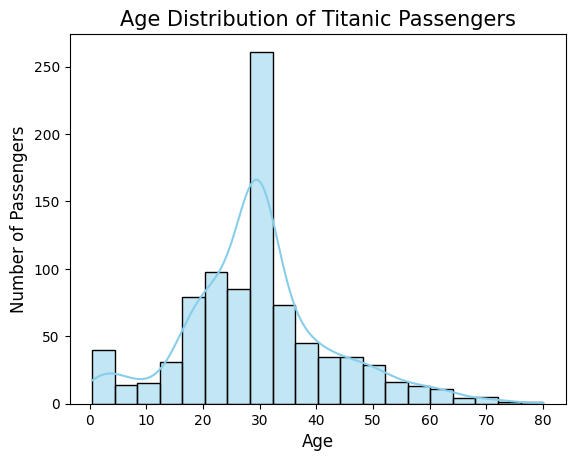

In [12]:
plt.Figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x = "Age",
    bins=20,
    kde=True,
    color='skyblue',
    edgecolor = 'black'
)

plt.title("Age Distribution of Titanic Passengers", fontsize=15)
plt.xlabel("Age",fontsize=12)
plt.ylabel("Number of Passengers",fontsize=12)

plt.savefig("age_distribution_histogram.png", dpi=300, bbox_inches='tight')
plt.show()

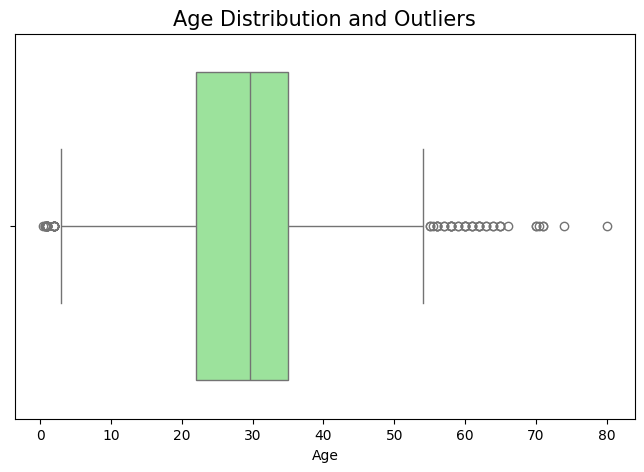

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Age",
    color="lightgreen"
)

plt.title("Age Distribution and Outliers", fontsize=15)
plt.xlabel("Age")

plt.savefig("age_boxplot.png", dpi=300)
plt.show()

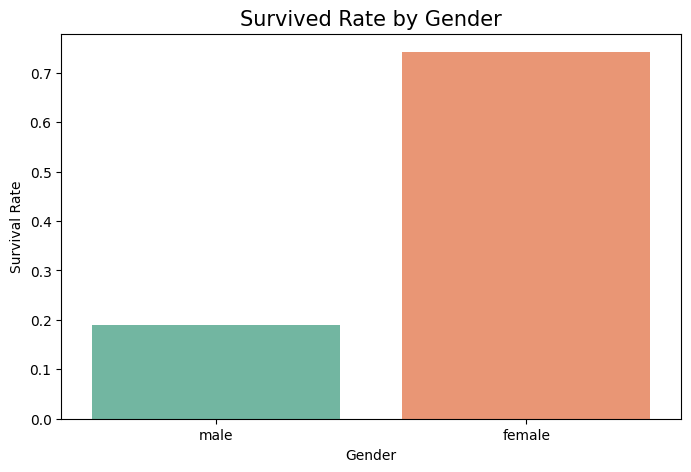

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived",
    hue="Sex",
    palette="Set2",
    errorbar=None
)
plt.title("Survived Rate by Gender", fontsize=15)
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.savefig("gender_survival_bar.png", dpi=300)
plt.show()

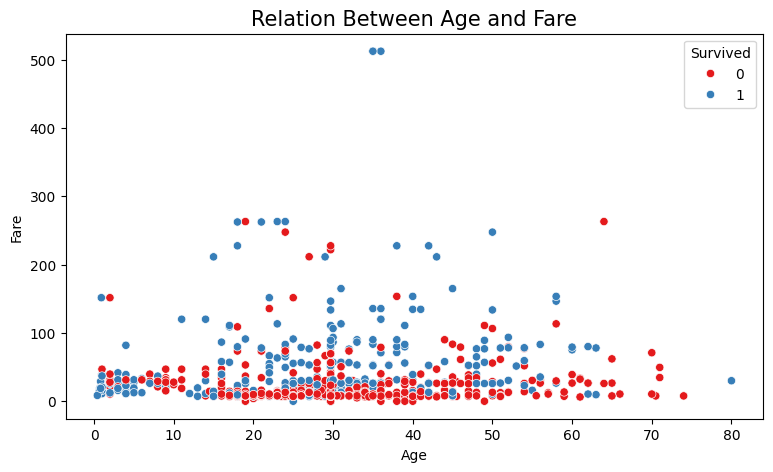

In [20]:
plt.figure(figsize=(9,5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    palette="Set1",
)

plt.title("Relation Between Age and Fare", fontsize=15)
plt.xlabel("Age")
plt.ylabel("Fare")

plt.savefig("gender_survival_bar.png", dpi=300)
plt.show()

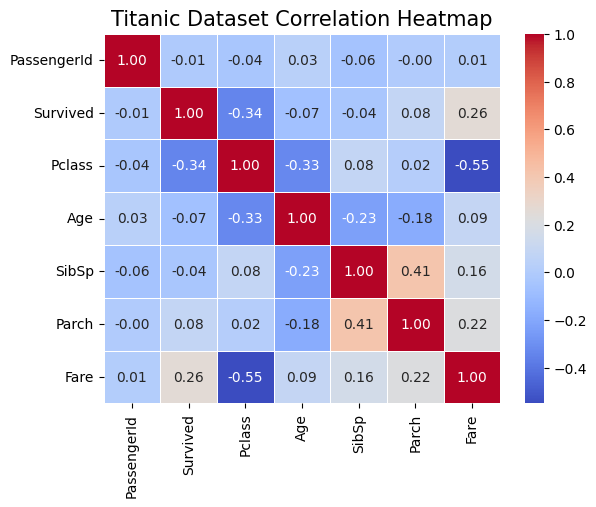

In [ ]:
plt.Figure(figsize=(10,7))

numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Titanic Dataset Correlation Heatmap", fontsize=15)

plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()